# PPKS 09: Analitički signal

***

Ranije smo rekli da realni signali imaju simetričan frekvencijski spektar.
To se može vidjeti na primjeru kosinusa. Za $x(t)=A\cos(2\pi f_0 t)$ imamo dvije frekvencijske komponente. Jednu na frekvenciji $-f_0$ i drugu na $f_0$, obje amplitude $\frac{A}{2}$. To je zato što je kosinus realan signal i nema imaginarni dio pa, kad ga pišemo u kompleksnom obliku, koristimo dvije kompleksne eksponencijalne komponente jednake amplitude: 

$$
\cos(2\pi f_0 t)=\frac{1}{2}[e^{j2\pi f_0 t}+e^{-j2\pi f_0 t}]
$$

Prema Eulerovoj formuli vrijedi
$
e^{j\Phi}=\cos(\Phi)+j\sin(\Phi)
$
što znači da kompleksna eksponencijala opisuje točku $(\cos\Phi,\sin\Phi)$ u kompleksnoj ravnini. Kako se faza $\Phi$ mijenja s vremenom, ta točka kruži po jediničnoj kružnici pa kompleksnu eksponencijalu možemo promatrati kao rotirajući vektor.
Vrijednost kompleksnog signala $z(t)=a+jb$ tada određuje položaj vrha rotirajućeg vektora. Duljina tog vektora predstavlja trenutnu amplitudu $A(t)=\sqrt{a^2+b^2}$, dok njegov kut predstavlja trenutnu fazu $\Phi(t)=\arg z(t)$. 

Kompleksne eksponencijale $e^{j2\pi f_0 t}$ i $e^{-j2\pi f_0 t}$ predstavljaju rotacije u suprotnim smjerovima u kompleksnoj ravnini. Pozitivne frekvencije odgovaraju smjeru suprotnom od kazaljke sata (engl. counter-clockwise), a negativne u smjeru kazalje (engl. clockwise).
Kod realnih signala promatramo samo projekciju tih rotirajućih vektora na realnu os. Budući da realni signal nastaje zbrajanjem pozitivne i negativne frekvencijske komponente koje su međusobno kompleksno konjugirane, njegov spektar mora biti simetričan.

Problem je što iz same projekcije na realnu os nije moguće jednoznačno odrediti smjer rotacije u kompleksnoj ravnini. Zato iz realnog signala ne možemo izravno odrediti trenutnu amplitudu i fazu rotirajućeg vektora. Kako bismo to omogućili, konstruiramo kompleksni signal koji zadržava samo pozitivne frekvencijske komponente realnog signala, a uklanja negativne. Na taj način ostaje samo jedan smjer rotacije u kompleksnoj ravnini. Takav kompleksni zapis realnog signala nazivamo **analitički signal**.


***

Analitički signal $z(t)$ realnog signala $x(t)$ pišemo:

$$
z(t)=x(t)+j\hat{x}(t)
$$

gdje je $\hat{x}(t)$ **Hilbertova transformacija** signala $x(t)$. Hilbertova transformacija pomiče fazu svake frekvencijske komponente za $\frac{\pi}{2}$ na sljedeći način:

- ako s $X(f)$ označimo spektar signala $x(t)$, spektar signala nakon Hilbertove transformacije izgledat će ovako:

$$
\hat{X}(f)=-j\cdot \text{sgn}(f)X(f)
$$

gdje je $\text{sgn}(f)$ funkcija predznaka:

$$
\text{sgn}(f) = \begin{cases} 1, & f > 0 \\ 0, & f = 0 \\ -1, & f < 0 \end{cases}
$$

Množenje spektra s $j$ nam u kompleksnoj ravnini predstavlja pomak od $\frac{\pi}{2}$ jer je $j=e^{j\frac{\pi}{2}}$. To znači da Hilbertova transformacija svakoj pozitivnoj frekvencijskoj komponenti dodaje fazni pomak od $-\frac{\pi}{2}$, a svakoj negativnoj od $+\frac{\pi}{2}$.

***

Primjer: Za signal $s(t) = \cos(2\pi f_0 t)$ spektar je:

$$
S(f) = \frac{1}{2}\delta(f - f_0) + \frac{1}{2}\delta(f + f_0)
$$

Nakon primjene Hilbertove transformacije dobivamo 

$$
\hat{S}(f) = -\frac{1}{2j}\delta(f - f_0) + \frac{1}{2j}\delta(f + f_0)
$$

Taj spektar odgovara spektru sinusa. To i očekujemo budući da Hilbertova transformacija pozitivnim frekvencijama dodaje fazni pomak od $-\frac{\pi}{2}$. Dakle, Hilbertova transformacija kosinusa daje sinus
pa je analitički signal:

$$
z(t) = \cos(2\pi f_0 t) + j\sin(2\pi f_0 t) = e^{j2\pi f_0 t}
$$

Kad pogledamo spektar $Z(f)$, vidimo da više nema negativne frekvencijske komponente, a da je pozitivna frekvencijska komponenta na $f_0$ dvostruko veće amplitude nego u realnom spektru. Odnosno, sad imamo samo jedan smjer rotacije vektora u kompleksnoj ravnini. Spektar analitičkog signala izgleda ovako:

$$
Z(f) = \begin{cases} 0, & f < 0 \\ S(f), & f = 0 \\ 2S(f), & f > 0 \end{cases}
$$

Dakle, analitički signal zadržava svu informaciju originalnog realnog signala, ali uklanja redundantne negativne frekvencije čime omogućuje jednoznačno određivanje trenutne amplitude i faze:

$$
z(t)=A(t)e^{j\Phi(t)}
$$

gdje su:

$$
A(t)=|z(t)|
$$

$$
\Phi(t)=\text{arg }z(t)
$$


***

### Implementacija

Analitički signal u Pythonu možemo izračunati funkcijom ```scipy.signal.hilbert()```. Važno je primijetiti da ova funkcija ne vraća samo Hilbertovu transformaciju, nego cijeli analitički signal. Dakle, realni dio signala koji dobijemo kao izlaz te funkcije jednak je originalnom signalu, a imaginarni je Hilbertova transformacija pa, ako želimo prikazati samo Hilbertovu transformaciju, dovoljno je uzeti imaginarni dio rezultata:
```x_h = np.imag(hilbert(x))```.

U sljedećem primjeru generiramo kosinusni signal frekvencije $50\ \text{Hz}$ i računamo njegov analitički signal. Na trećem grafu prikazan je spektar analitičkog signala. Vidimo da je negativna frekvencijska komponenta uklonjena, dok je pozitivna komponenta udvostručena. Na taj način analitički signal zadržava svu informaciju originalnog signala koristeći samo pozitivni dio spektra.


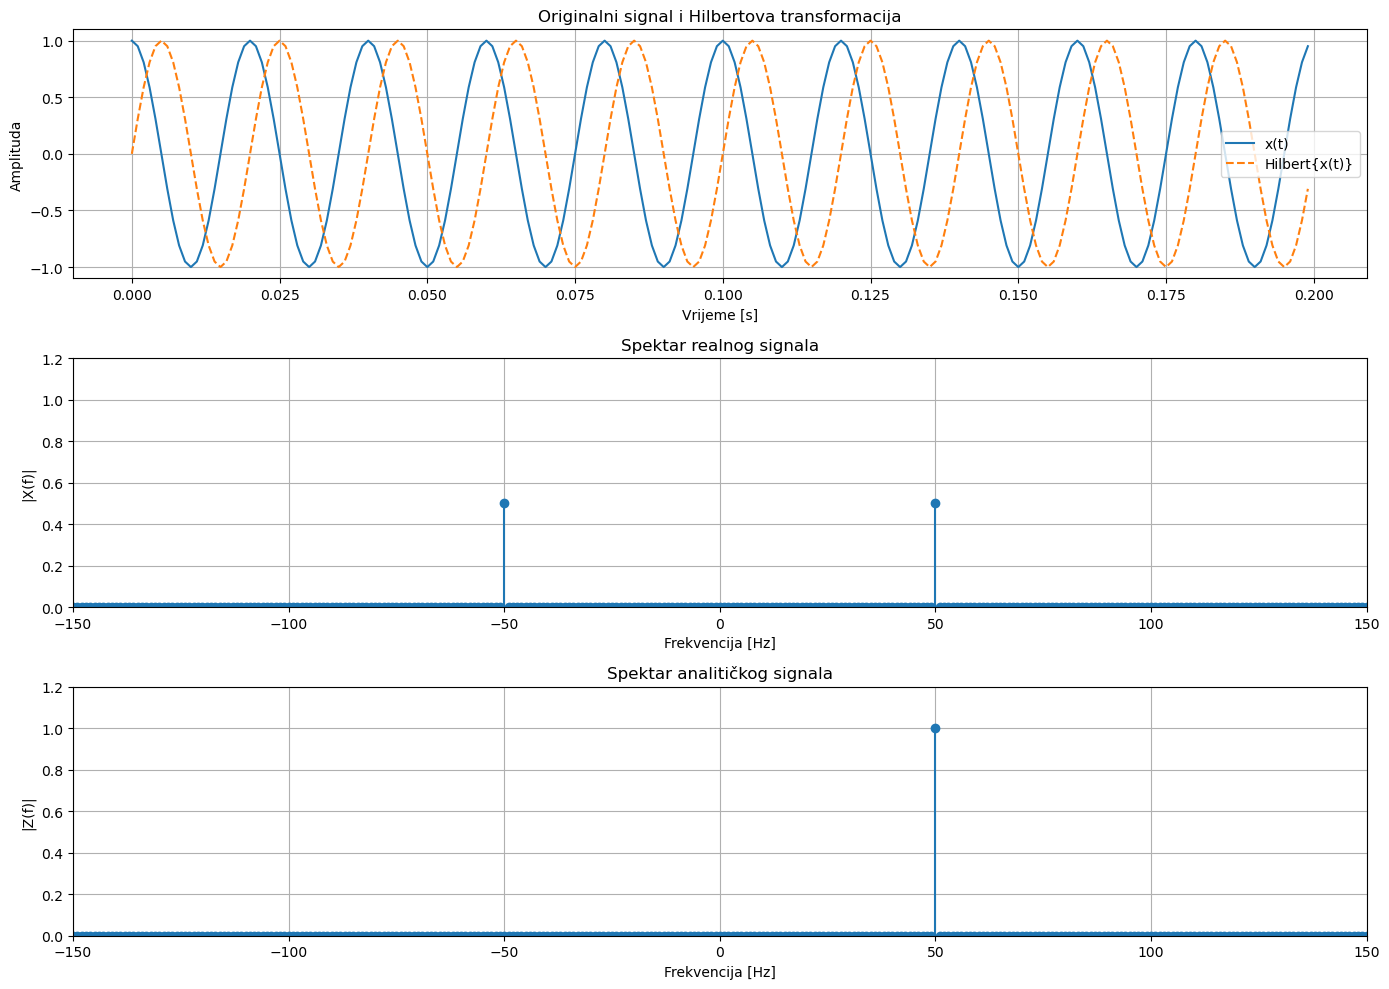

In [1]:
### Analitički signal


import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert


fs = 1000          # frekvencija uzorkovanja
T = 1              # trajanje signala
f0 = 50            # frekvencija kosinusa

t = np.arange(0, T, 1/fs)

x = np.cos(2*np.pi*f0*t)


x_h = np.imag(hilbert(x))  # samo za prikaz

# vraća analitički signal
z = hilbert(x)

# Fourier
N = len(x)

X = np.fft.fftshift(np.fft.fft(x))/N
XH = np.fft.fftshift(np.fft.fft(x_h))/N
Z = np.fft.fftshift(np.fft.fft(z))/N

f = np.fft.fftshift(np.fft.fftfreq(N, d=1/fs))



plt.figure(figsize=(14,10))


plt.subplot(3,1,1)
plt.plot(t[:200], x[:200], label='x(t)')
plt.plot(t[:200], x_h[:200], '--', label='Hilbert{x(t)}')
plt.xlabel('Vrijeme [s]')
plt.ylabel('Amplituda')
plt.title('Originalni signal i Hilbertova transformacija')
plt.legend()
plt.grid()


plt.subplot(3,1,2)
plt.stem(f, np.abs(X), basefmt=" ")
plt.xlim(-150,150)
plt.xlabel('Frekvencija [Hz]')
plt.ylabel('|X(f)|')
plt.title('Spektar realnog signala')
plt.ylim(0, 1.2)
plt.grid()


plt.subplot(3,1,3)
plt.stem(f, np.abs(Z), basefmt=" ")
plt.xlim(-150,150)
plt.xlabel('Frekvencija [Hz]')
plt.ylabel('|Z(f)|')
plt.title('Spektar analitičkog signala')
plt.ylim(0, 1.2)
plt.grid()

plt.tight_layout()
plt.show()

***

## Implementacija demodulacije AM signala

Demodulacija AM signala započinje izdvajanjem ovojnice pomoću analitičkog signala. Znamo da nam ovojnica ima oblik $e(t)=A_c(1+k_am(t))$. To znači da nakon što pretvorimo primljeni signal u analitički (funkcijom ```scipy.signal.hilbert()```), moramo uzeti modul tog signala:

$$
e(t)=|z(t)|
$$
što radimo s ```envelope = np.abs(analytic)```. Kad imamo ovojnicu, do poruke dolazimo računanjem:

$$
m(t)=\frac{e(t)-A_c}{A_ck_a}
$$

Cijeli postupak je dan u nastavku.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert

fs = 200000
T = 0.005
t = np.linspace(0, T, int(fs * T), endpoint=False)

f_c = 20000
k_a = 0.8
Ac = 2

m_orig = (0.5 * np.sin(2 * np.pi * 800 * t) +
          0.3 * np.sin(2 * np.pi * 1600 * t))
m_orig /= np.max(np.abs(m_orig))  #da signal ide od -1 do 1

s_am = Ac*(1 + k_a * m_orig) * np.cos(2 * np.pi * f_c * t)

analytic = hilbert(s_am)
envelope = np.abs(analytic)
demod = (envelope - Ac) / (Ac*ka)

r = np.corrcoef(m_orig, demod)[0, 1]
print(f"Korelacija original vs demodulirani: {r:.6f}")

fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

axes[0].plot(t * 1000, m_orig, linewidth=2)
axes[0].set_title('Originalna poruka m(t)')
axes[0].set_ylabel('Amplituda')

axes[1].plot(t * 1000, s_am, linewidth=1)
axes[1].set_title('AM signal s(t)')
axes[1].set_ylabel('Amplituda')

axes[2].plot(t * 1000, s_am, linewidth=0.8, alpha=0.5, label='AM signal')
axes[2].plot(t * 1000, envelope, linewidth=2, label='ovojnica')
axes[2].set_title('Detekcija ovojnice')
axes[2].set_ylabel('Amplituda')
axes[2].legend()

axes[3].plot(t * 1000, demod, linewidth=2, label=f'Demodulirani signal (r={r:.4f})')
axes[3].plot(t * 1000, m_orig, '--', linewidth=1.5, label='Original')
axes[3].set_title('Rekonstruirana poruka')
axes[3].set_ylabel('Amplituda')
axes[3].set_xlabel('Vrijeme (ms)')
axes[3].legend()

plt.tight_layout()
plt.show()

***

# Kutne modulacije


Kod amplitudne modulacije (AM) informacijski signal $m(t)$ se prenosi promjenom amplitude nosioca. Međutim, amplituda signala osjetljiva je na šum i smetnje pa se u mnogim komunikacijskim sustavima koriste modulacije kod kojih amplituda ostaje konstantna, a informacija se prenosi promjenom faze, odnosno kuta nosioca. 
Takve modulacije nazivamo **kutnim modulacijama**. 

Opći oblik kutno moduliranog signala je:

$$
s(t)=A_c\cos(\phi(t))
$$

Kut $\phi(t)$ nazivamo trenutnom fazom signala. Kod **fazne modulacije** mijenja se cijela trenutna faza ovisno o informacijskom signalu, a kod **frekvencijske modulacije** se mijenja trenutna frekvencija koja posljedično mijenja i fazu. Faza i frekvencija su povezane na sljedeći način:

Trenutna kutna frekvencija $\omega_i(t)$ predstavlja promjenu kuta (faze) u vremenu pa ju računamo kao derivaciju trenutne faze:

$$
\omega_i(t)=\frac{d\phi(t)}{dt}
$$

Budući da vrijedi:

$$
\omega=2\pi f
$$

trenutna frekvencija $f_i(t)$ je:

$$
f_i(t)=\frac{1}{2\pi}\frac{d\phi(t)}{dt}
$$

Valja napomenuti kako kutna frekvencija zapravo govori koliko se brzo vektor rotira u kompleksnoj ravnini. Zato ju računamo u $[rad/s]$. Frekvencija, s druge strane, govori o broju ciklusa u sekundi, a jedan ciklus je u ovom slučaju jednak $2\pi$.


---

### Fazna modulacija (PM)

Kod **fazne modulacije (engl. Phase Modulation, PM)** trenutna faza nosioca mijenja se proporcionalno informacijskom signalu:

$$
\phi(t)=2\pi f_c t+k_p m(t)
$$

gdje je $k_p$ konstanta osjetljivosti faznog modulatora. 

PM signal tada zapisujemo kao:

$$
s_{PM}(t)=A_c\cos\left(2\pi f_c t+k_p m(t)\right)
$$



### Frekvencijska modulacija (FM)

Kod **frekvencijske modulacije (engl. Frequency Modulation, FM)** informacijski signal utječe samo na trenutnu frekvenciju nosioca:

$$
f_i(t)=f_c+k_f m(t)
$$

gdje je $k_f$ osjetljivost frekvencijskog modulatora.

Za trenutnu frekvenciju vrijedi:

$$
f_i(t)=\frac{1}{2\pi}\frac{d\phi(t)}{dt}
$$

To znači da trenutnu fazu moduliranog signala dobivamo integriranjem:

$$
\phi(t)=2\pi\int_0^t f_i(\tau)d\tau
$$

Odnosno,

$$\phi(t)=2\pi\int_0^t\left(f_c+k_f m(\tau)\right)d\tau$$

$$\phi(t)=2\pi f_c t+2\pi k_f\int_0^t m(\tau)d\tau$$

pa FM signal zapisujemo kao:

$$
s_{FM}(t)=A_c\cos\left(2\pi f_c t+2\pi k_f\int_0^t m(\tau)d\tau\right)
$$



Kod FM modulacije informacijski signal određuje frekvenciju, odnosno brzinu rotacije vektora u kompleksnoj ravnini. Pozitivan dio signala povećava trenutnu frekvenciju iznad frekvencije nosioca, dok je negativan dio smanjuje ispod frekvencije nosioca. Razlika u odnosu na faznu modulaciju je u tome što je kod FM modulacije trenutna frekvencija proporcionalna informacijskom signalu, dok je faza proporcionalna **integralu** tog signala.


***

Primjer: Uzmimo za informacijski signal:
$m(t)=A_m\cos(2\pi f_m t)$


Kod PM modulacije trenutna faza je proporcionalna informacijskom signalu:

$$\phi_{PM}(t)=2\pi f_c t+k_p m(t)$$

pa PM signal postaje:

$$
s_{PM}(t)=A_c\cos\left(2\pi f_c t+k_p A_m\cos(2\pi f_m t)\right)
$$

Za FM faza je:

$$\phi(t)=2\pi f_c t+2\pi k_f\int_0^t A_m\cos(2\pi f_m \tau)\,d\tau$$

Integral kosinusa je sinus:

$$\int_0^t\cos(2\pi f_m \tau)\,d\tau=\frac{1}{2\pi f_m}\sin(2\pi f_m t)$$

pa dobivamo:

$$\phi(t)=2\pi f_c t+\frac{k_f A_m}{f_m}\sin(2\pi f_m t)$$

FM signal tada postaje:

$$
s_{FM}(t)=A_c\cos\left(2\pi f_c t+\frac{k_f A_m}{f_m}\sin(2\pi f_m t)\right)
$$


Parametar $k_f$ određuje koliko snažno informacijski signal utječe na trenutnu frekvenciju nosioca.
Ako je $k_f$ malen, trenutna frekvencija samo malo odstupa od frekvencije nosioca. Takav FM signal zauzima uži frekvencijski pojas jer se u spektru pojavljuje manji broj bočnih komponenti. Prednost toga je, dakle, manja potrošnja spektra, ali su promjene trenutne frekvencije manje izražene pa je signal osjetljiviji na šum i zahtijeva precizniju demodulaciju.
S druge strane, ako je $k_f$ velik, informacijski signal uzrokuje veća odstupanja trenutne frekvencije od frekvencije nosioca što rezultira većim brojem bočnih frekvencijskih komponenti u spektru pa FM signal zauzima širi frekvencijski pojas. Takvi signali imaju bolju otpornost na šum, ali troše više spektra.




***

U nastavku je dan primjer frekvencijske modulacije sinusnog informacijskog signala.

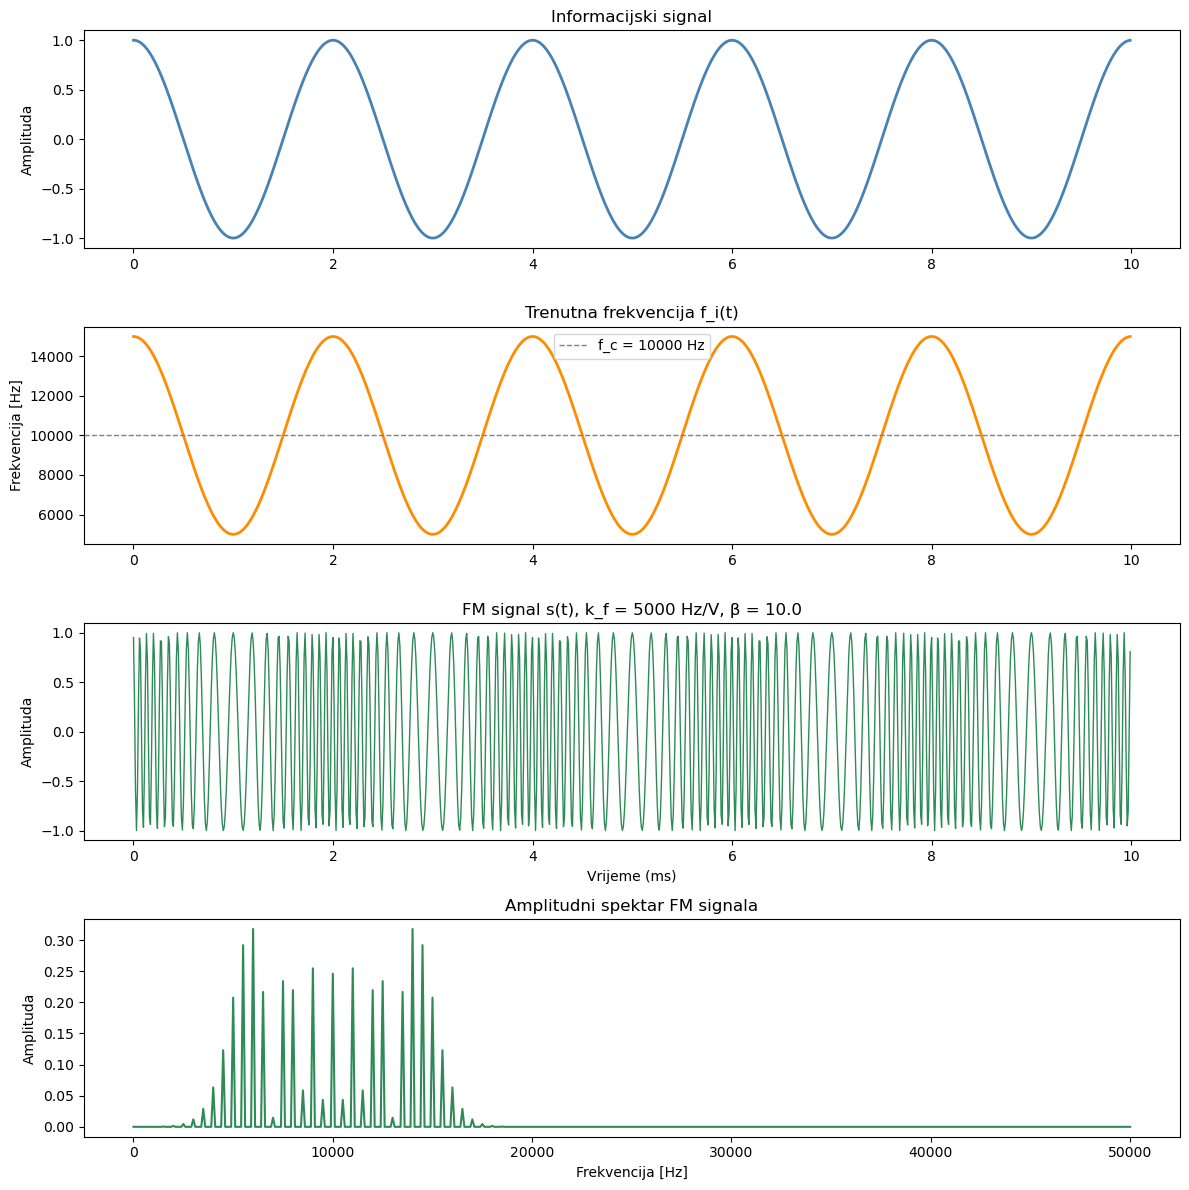

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fs = 100_000
T = 0.01
t = np.linspace(0, T, int(fs * T), endpoint=False)

f_m = 500
f_c = 10_000
A_c = 1.0
k_f = 5000      

m_t = np.cos(2 * np.pi * f_m * t)

# Integriranje informacijskog signala 
integral_m = np.cumsum(m_t) / fs

s_fm = A_c * np.cos(2 * np.pi * f_c * t + 2 * np.pi * k_f * integral_m)

inst_freq = f_c + k_f * m_t

# Spektar
N = len(s_fm)
S_f = np.abs(np.fft.rfft(s_fm)) / N * 2
freqs = np.fft.rfftfreq(N, 1/fs)

fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=False)

axes[0].plot(t * 1000, m_t, linewidth=2, color='steelblue')
axes[0].set_title('Informacijski signal')
axes[0].set_ylabel('Amplituda')

axes[1].plot(t * 1000, inst_freq, linewidth=2, color='darkorange')
axes[1].set_title('Trenutna frekvencija f_i(t)')
axes[1].set_ylabel('Frekvencija [Hz]')
axes[1].axhline(f_c, color='gray', linestyle='--', linewidth=1, label=f'f_c = {f_c} Hz')
axes[1].legend()

axes[2].plot(t * 1000, s_fm, linewidth=1, color='seagreen')
axes[2].set_title(f'FM signal s(t), k_f = {k_f} Hz/V, β = {k_f/f_m:.1f}')
axes[2].set_ylabel('Amplituda')
axes[2].set_xlabel('Vrijeme (ms)')

axes[3].plot(freqs, S_f, color='seagreen')
axes[3].set_title('Amplitudni spektar FM signala')
axes[3].set_xlabel('Frekvencija [Hz]')
axes[3].set_ylabel('Amplituda')

plt.tight_layout()
plt.show()


Iako je informacijski signal u slučaju FM modulacije analogan (jer se radi o analognoj modulaciji), u računalnoj implementaciji se prikazuje u diskretnom obliku pa se integral poruke aproksimira diskretnom kumulativnom sumom pomoću funkcije `np.cumsum()`. 

Mijenjanjem parametra $k_f$ može se vidjeti prije spomenuti utjecaj osjetljivosti modulatora. 
Ako se parametar smanji, pojas frekvencija FM signala bit će uži, ali će na samom signalu biti teže uočiti promjene do kojih je došlo prilikom modulacije. Zato kažemo da veći $k_f$ poboljšava robusnost prijenosa informacije na šum, ali istovremeno povećava zauzeti frekvencijski pojas FM signala.

***

## Analogne modulacije

U usporedbi s amplitudnom modulacijom, frekvencijska modulacija obično zahtijeva veću širinu pojasa. Razlog tome je što se kod FM modulacije informacija prenosi promjenom trenutne frekvencije nosioca, a, budući da je faza integral frekvencije, takva modulacija u frekvencijskoj domeni stvara velik broj dodatnih bočnih frekvencijskih komponenti oko frekvencije nosioca. Što su promjene trenutne frekvencije veće, spektar FM signala postaje širi.

Kod amplitudne modulacije situacija je jednostavnija. AM signal sastoji se od nosioca i dvije bočne frekvencijske komponente pa je potrebna širina pojasa približno jednaka dvostrukoj širini pojasa informacijskog signala:

$$
B_{AM}\approx 2B_m
$$
gdje je $B_m$ širina pojasa informacijskog signala. 

Kod FM modulacije širina pojasa može biti višestruko veća od širine pojasa informacijskog signala jer promjene trenutne frekvencije stvaraju velik broj dodatnih bočnih komponenti oko frekvencije nosioca. Najveće odstupanje trenutne frekvencije od frekvencije nosioca zovemo frekvencijska devijacija:

$$
\Delta f=k_fA_m
$$

pa će trenutna frekvencija varirati u granicama:
$
f_c-\Delta f \le f_i(t) \le f_c+\Delta f
$.
Dakle, veća frekvencijska devijacija rezultira širim spektrom FM signala.

Iako FM zauzima više spektra, ta modulacija pruža i znatno bolju otpornost na šum. Razlog je što se kod FM modulacije informacija nalazi u promjenama frekvencije, a ne amplitude signala. Budući da šum u komunikacijskim kanalima najčešće utječe upravo na amplitudu, FM signal je manje osjetljiv na smetnje od AM signala.

Fazne modulacije posebno su važne kod digitalnih komunikacijskih sustava. Kod digitalnih signala informacija je diskretna pa se prirodno može prenositi diskretnim promjenama faze nosioca. Svako fazno stanje tada može predstavljati određenu kombinaciju bitova pa su fazne modulacije temelj mnogih modernih digitalnih komunikacijskih sustava.